## ProShares Short QQQ

In [1]:
import os
import sys
import requests
import datetime as dt
import numpy as np
from dotenv import load_dotenv
from pathlib import Path
import requests
import pandas as pd
import talib as ta
import plotly.graph_objs as go

import ipywidgets as widgets
from ipywidgets import Dropdown, Text, Button, Output
from IPython.display import display

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.reques_api import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension

In [2]:
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()

In [3]:
start = '1999-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')

#### Nasdaq 100の時系列データを取得

In [4]:
qqq = 'NQ=F'
market = None

response = request_api.update_stock_timeseries_data(
    code=qqq,
    market=market,
    start=start,
    end=end
)
response

{'result': True}

In [5]:
qqq_timeseries_df = request_api.get_stock_time_series_data(
    code=qqq,
    market=market,
    start=start,
    end=end
)
qqq_timeseries_df

取得件数: 6585


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1289450,NQ=F,None,2000-09-18,3653.50,3785.50,3602.00,3721.00,72994,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1289451,NQ=F,None,2000-09-19,3804.00,3817.00,3656.00,3658.50,70029,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1289452,NQ=F,None,2000-09-20,3853.00,3874.00,3715.50,3801.50,78832,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1289453,NQ=F,None,2000-09-21,3765.00,3874.00,3744.00,3852.00,70719,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1289454,NQ=F,None,2000-09-22,3776.00,3780.00,3615.00,3673.00,55926,3741.20,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6580,1296030,NQ=F,None,2026-10-12,30898.25,31289.25,30844.25,31145.50,452221,31285.15,...,29448.446998,58.016734,True,NaN,NaN,NaN,NaN,NaN,81.91453,False
6581,1296031,NQ=F,None,2026-10-13,30791.50,30906.00,30591.25,30876.00,532591,31191.00,...,29509.803237,57.717920,True,NaN,NaN,NaN,408.586265,NaN,NaN,False
6582,1296032,NQ=F,None,2026-10-14,30182.75,30891.50,30078.00,30791.50,749259,31047.30,...,29573.744921,57.248357,True,NaN,NaN,NaN,NaN,NaN,NaN,False
6583,1296033,NQ=F,None,2026-10-15,30143.75,30196.75,29622.50,30154.75,816479,30797.65,...,29622.371518,55.207889,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### ProShares Short QQQの時系列データを取得

In [6]:
psq = 'PSQ'
market = None

response = request_api.update_stock_timeseries_data(
    code=psq,
    market=market,
    start=start,
    end=end
)
response

{'result': True}

In [7]:
psq_timeseries_df = request_api.get_stock_time_series_data(
    code=psq,
    market=market,
    start=start,
    end=end
)
psq_timeseries_df

取得件数: 5113


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1296035,PSQ,None,2006-06-21,969.029541,969.029541,969.029541,969.029541,10,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1296036,PSQ,None,2006-06-22,985.693604,986.682139,976.232057,976.232057,730,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1296037,PSQ,None,2006-06-23,985.551697,991.341549,980.891475,991.341549,835,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1296038,PSQ,None,2006-06-26,985.693604,990.212560,984.140253,985.834786,810,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1296039,PSQ,None,2006-06-27,1004.757507,1005.463591,985.693240,985.693240,3135,981.626235,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5108,1301143,PSQ,None,2026-10-12,24.660000,24.700001,24.530001,24.530001,13653100,24.378000,...,24.450051,-57.542901,False,NaN,NaN,NaN,NaN,NaN,NaN,True
5109,1301144,PSQ,None,2026-10-13,24.740000,24.889999,24.719999,24.870001,17608600,24.520000,...,24.432631,-56.646461,False,NaN,NaN,-0.258041,NaN,NaN,NaN,False
5110,1301145,PSQ,None,2026-10-14,25.230000,25.320000,24.840000,24.940001,27465400,24.632000,...,24.418901,-55.271920,False,NaN,NaN,NaN,NaN,NaN,NaN,False
5111,1301146,PSQ,None,2026-10-15,25.260000,25.709999,25.219999,25.600000,29444400,24.876001,...,24.424418,-48.271152,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### チャート

In [8]:
def stock_prices_and_index(
        code: str,
        name: str,
        start: str,
        end: str,
        market: str | None = None,
        df_sp: pd.DataFrame | None = None,
        index_name: str | None = None,
        df_index: pd.DataFrame | None = None,
    ):
    # /api/v1/time_series_data/stock/
    response = request_api.get_stock_time_series_data(
        code=code,
        market=market,
        start=start,
        end=end
    )
    df_stock = pd.DataFrame(response)

    # S&P500を統合
    if df_sp is not None:
        df_sp_tmp = df_sp.copy() if df_sp is not None else pd.DataFrame()
        if "date" not in df_sp_tmp.columns:
            df_sp_tmp = df_sp_tmp.reset_index()

        df_sp_tmp["date"] = pd.to_datetime(df_sp_tmp["date"])
        df_sp_tmp = df_sp_tmp.set_index("date")
        df_sp_tmp = df_sp_tmp.loc[start:end]

    # INDEXを統合
    if df_index is not None:
        df_index_tmp = df_index.copy() if df_index is not None else pd.DataFrame()
        if "date" not in df_index_tmp.columns:
            df_index_tmp = df_index_tmp.reset_index()
        df_index_tmp["date"] = pd.to_datetime(df_index_tmp["date"])
        df_index_tmp = df_index_tmp.set_index("date")
        df_index_tmp = df_index_tmp.loc[start:end]

    # 株価時系列データを整形
    df = df_stock.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date")
    df = df.loc[start:end]


    # インデックスを揃えて結合
    if df_sp is not None:
        df["MA50_SP"] = df_sp_tmp["ma50"].reindex(df.index)
        df["MA200_SP"] = df_sp_tmp["ma200"].reindex(df.index)
    if df_index is not None:
        df["MA50_" + index_name] = df_index_tmp["ma50"].reindex(df.index)
        df["MA200_" + index_name] = df_index_tmp["ma200"].reindex(df.index)

    show_plot = ShowPlot()
    fig = show_plot.create_basic_chart(
        df=df.reset_index(),
        code=code,
        name=name,
        start=start,
        end=end,
        ma5=False,
        ma25=False,
        ma50=True,
        ma100=False,
        ma150=False,
        ma200=True,
    )
    # ★ 2つのY軸を定義（左：HYMC、右：SP500 & GOLD）
    fig.update_layout(
        yaxis=dict(
            title=f"{name} Price",
            side="left"
        ),
        yaxis2=dict(
            title="SP500 / WTI",
            overlaying="y",
            side="right"
        )
    )

    # --- SP500（右軸） ---
    if df_sp is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA50_SP"],
                name="SP_MA50",
                line={"color": "blue", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA200_SP"],
                name="SP_MA200",
                line={"color": "gray", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    # --- INDEX（右軸） ---
    if df_index is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA50_" + index_name],
                name=index_name + "_MA50",
                line={"color": "orange", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA200_" + index_name],
                name=index_name + "_MA200",
                line={"color": "yellow", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    return fig

#### PSQのチャート

In [9]:
name = "ProShares Short QQQ"
start = dt.datetime(2025, 1, 1).strftime("%Y-%m-%d")
# グラフ領域の作成
fig = stock_prices_and_index(
    code=psq,
    name=name,
    start=start,
    end=end,
    market=None,
    df_sp=None,
    df_index=None
)
fig.show()

取得件数: 656


In [10]:
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"{psq}_{start}_{end}.png"
# 既存の画像ファイルが存在する場合は削除
if output_path.exists():
    output_path.unlink()
# 画像ファイルを保存
fig.write_image(str(output_path), width=1600, height=900, scale=2)
# 保存完了のメッセージを表示
print("saved:", output_path)

saved: /workspace/data/figures/PSQ_2025-01-01_2026-10-17.png


#### Nasdaq 100 のチャート

In [11]:
name = "Nasdaq 100"
start = dt.datetime(2025, 1, 1).strftime("%Y-%m-%d")
# グラフ領域の作成
fig = stock_prices_and_index(
    code=qqq,
    name=name,
    start=start,
    end=end,
    market=None,
    df_sp=None,
    df_index=None
)
fig.show()

取得件数: 658


In [12]:
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"{qqq}_{start}_{end}.png"
# 既存の画像ファイルが存在する場合は削除
if output_path.exists():
    output_path.unlink()
# 画像ファイルを保存
fig.write_image(str(output_path), width=1600, height=900, scale=2)
# 保存完了のメッセージを表示
print("saved:", output_path)

saved: /workspace/data/figures/NQ=F_2025-01-01_2026-10-17.png


#### 時系列データを保存

In [13]:
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{psq}_data_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 既存の CSV ファイルが存在する場合は削除
if output_path.exists():
    output_path.unlink()
# CSV ファイルを新規作成する準備完了
psq_df = psq_timeseries_df.copy()
psq_df = psq_df.reset_index()
psq_df["date"] = pd.to_datetime(psq_df["date"])
psq_df = psq_df.set_index("date")
psq_df = psq_df.loc['2026-01-01':end]
psq_df.to_csv(output_path)
psq_df.head()

,index,id,stock_code,stock_market,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
date,,,,,,,,,,,,,,,,,,,,,
2026-01-02,4914,1300949,PSQ,None,29.549829,29.696260,29.091010,29.227681,10491300,29.167156,...,28.968392,9.988901,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-05,4915,1300950,PSQ,None,29.325302,29.383874,29.188632,29.266728,10686300,29.223776,...,28.965793,14.419875,True,29.223776,NaN,-0.042546,NaN,55.0,NaN,False
2026-01-06,4916,1300951,PSQ,None,29.061726,29.296015,29.042201,29.276491,12611700,29.241348,...,28.965371,17.980022,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-07,4917,1300952,PSQ,None,29.042200,29.120297,28.866482,29.091010,12183400,29.217918,...,28.955690,20.208316,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-08,4918,1300953,PSQ,None,29.227682,29.344826,29.091012,29.100774,16846100,29.192537,...,28.953729,23.998975,True,NaN,NaN,NaN,-0.046651,NaN,39.008547,False


In [14]:
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{qqq}_data_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 既存の CSV ファイルが存在する場合は削除
if output_path.exists():
    output_path.unlink()
# CSV ファイルを新規作成する準備完了
qqq_df = qqq_timeseries_df.copy()
qqq_df = qqq_df.reset_index()
qqq_df["date"] = pd.to_datetime(qqq_df["date"])
qqq_df = qqq_df.set_index("date")
qqq_df = qqq_df.loc['2026-01-01':end]
qqq_df.to_csv(output_path)
qqq_df.head()

,index,id,stock_code,stock_market,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
date,,,,,,,,,,,,,,,,,,,,,
2026-01-02,6386,1295836,NQ=F,None,25385.25,25803.75,25265.25,25478.50,554838,25726.60,...,25208.005251,1.677623,True,NaN,NaN,NaN,NaN,NaN,38.905983,False
2026-01-05,6387,1295837,NQ=F,None,25577.75,25708.00,25406.50,25431.75,461305,25639.35,...,25235.387134,-2.275250,True,NaN,NaN,NaN,80.296319,NaN,NaN,False
2026-01-06,6388,1295838,NQ=F,None,25822.00,25837.75,25527.50,25583.00,445573,25583.30,...,25249.239902,-3.948604,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-07,6389,1295839,NQ=F,None,25838.75,25996.25,25727.00,25831.25,477861,25601.55,...,25257.597911,-3.086314,True,NaN,NaN,89.843459,NaN,NaN,NaN,False
2026-01-08,6390,1295840,NQ=F,None,25687.50,25849.75,25569.00,25838.75,510805,25632.65,...,25270.708306,-3.871766,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### フィボナッチエクステンション

{'fib_levels_down': {'1.000': np.float64(24.09000015258789),
  '1.272': np.float64(23.046322586481427),
  '1.382': np.float64(22.624247100188374),
  '1.618': np.float64(21.718703329596)},
 'fib_levels_up': {'1.272': np.float64(28.970727594085762),
  '1.382': np.float64(29.392803080378815),
  '1.618': np.float64(30.29834685097119),
  '2.000': np.float64(31.764099903370706)},
 'swing_high': np.float64(27.9270500279793),
 'swing_low': np.float64(24.09000015258789),
 'df_with_fib':           date  index       id stock_code stock_market       open       high  \
 0   2026-01-02   4914  1300949        PSQ         None  29.549829  29.696260   
 1   2026-01-05   4915  1300950        PSQ         None  29.325302  29.383874   
 2   2026-01-06   4916  1300951        PSQ         None  29.061726  29.296015   
 3   2026-01-07   4917  1300952        PSQ         None  29.042200  29.120297   
 4   2026-01-08   4918  1300953        PSQ         None  29.227682  29.344826   
 ..         ...    ...      ... 

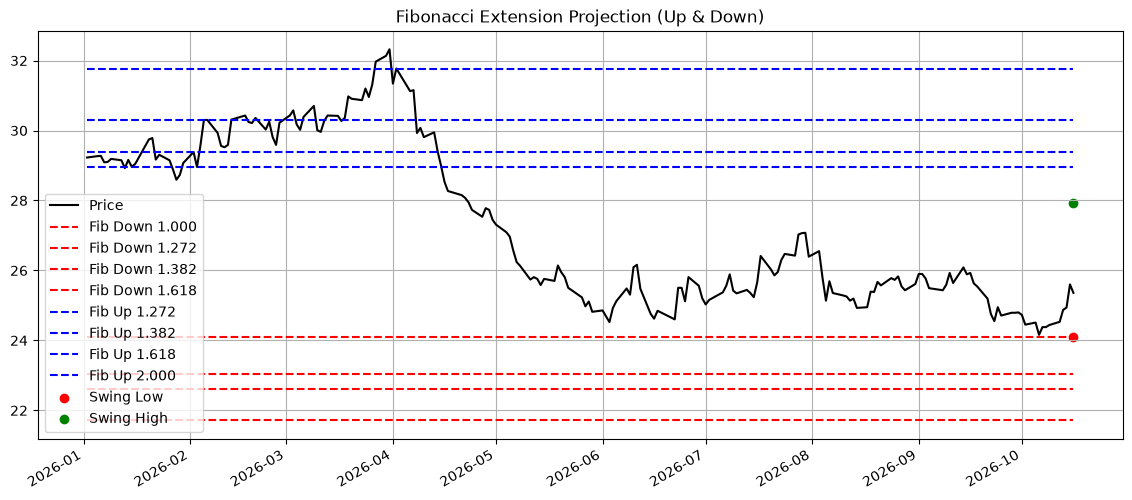

In [15]:
fib_result = fibonacci_extension.compute_fibonacci_extension(psq_df.copy().reset_index())
fib_result

In [16]:
output_dir = Path("/workspace/data/figures/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{psq}_fibonacci_extension_{dt.datetime.now().strftime('%Y-%m-%d')}.png"
# 既存の画像ファイルが存在する場合は削除
if output_path.exists():
    output_path.unlink()
# 画像ファイルを保存
fib_result["plot_obj"].savefig(output_path, dpi=300, bbox_inches="tight")
print("saved:", output_path)

saved: /workspace/data/figures/PSQ_fibonacci_extension_2026-10-17.png


{'fib_levels_down': {'1.000': np.float64(27009.5),
  '1.272': np.float64(25756.396),
  '1.382': np.float64(25249.626),
  '1.618': np.float64(24162.374)},
 'fib_levels_up': {'1.272': np.float64(32869.604),
  '1.382': np.float64(33376.374),
  '1.618': np.float64(34463.626),
  '2.000': np.float64(36223.5)},
 'swing_high': np.float64(31616.5),
 'swing_low': np.float64(27009.5),
 'df_with_fib':           date  index       id stock_code stock_market      open      high  \
 0   2026-01-02   6386  1295836       NQ=F         None  25385.25  25803.75   
 1   2026-01-05   6387  1295837       NQ=F         None  25577.75  25708.00   
 2   2026-01-06   6388  1295838       NQ=F         None  25822.00  25837.75   
 3   2026-01-07   6389  1295839       NQ=F         None  25838.75  25996.25   
 4   2026-01-08   6390  1295840       NQ=F         None  25687.50  25849.75   
 ..         ...    ...      ...        ...          ...       ...       ...   
 194 2026-10-12   6580  1296030       NQ=F         None

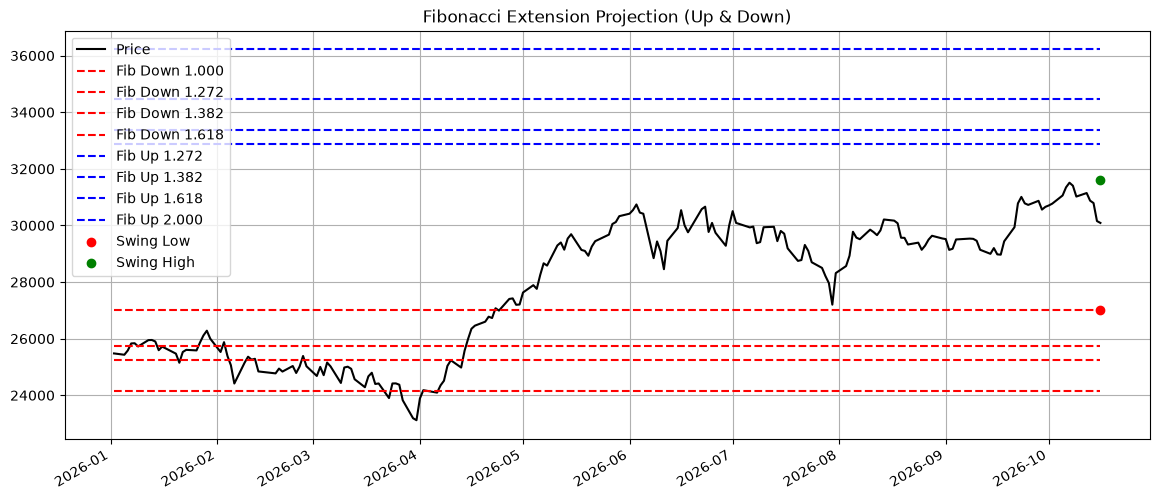

In [17]:
fib_result = fibonacci_extension.compute_fibonacci_extension(qqq_df.copy().reset_index())
fib_result

In [18]:
output_dir = Path("/workspace/data/figures/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{qqq}_fibonacci_extension_{dt.datetime.now().strftime('%Y-%m-%d')}.png"
# 既存の画像ファイルが存在する場合は削除
if output_path.exists():
    output_path.unlink()
# 画像ファイルを保存
fib_result["plot_obj"].savefig(output_path, dpi=300, bbox_inches="tight")
print("saved:", output_path)

saved: /workspace/data/figures/NQ=F_fibonacci_extension_2026-10-17.png
